                 Credit Card Fraud Detection and Transaction Risk Analytics
1. Project Objective
The objective of this project is to analyse historical credit card transactions, identify patterns associated with fraudulent activity, and develop a classification model for identifying potentially fraudulent transactions.

The project will also examine the financial and operational impact of fraud and develop an interactive Power BI dashboard for communicating fraud trends and transaction risk insights.

2. Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = "../data/raw/credit_card_fraud_detection_2026.csv"

fraud_df = pd.read_csv(file_path)

fraud_df.head()


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


In [3]:
fraud_df.shape

(100000, 43)

                                 Dataset Size
The raw dataset contains 100,000 transaction records and 43 variables.

In [4]:
fraud_df.columns

Index(['transaction_id', 'customer_id', 'card_id', 'merchant_id',
       'transaction_datetime', 'transaction_amount', 'merchant_category',
       'merchant_country', 'transaction_hour', 'transaction_day_of_week',
       'card_present', 'customer_age', 'customer_gender', 'customer_state',
       'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held',
       'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d',
       'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction',
       'distance_from_home_km', 'distance_from_last_tx_km',
       'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio',
       'used_chip', 'used_pin', 'transaction_channel', 'device_type',
       'browser', 'is_weekend', 'avg_transaction_amount_30d',
       'std_transaction_amount_30d', 'num_declined_last_30d',
       'num_chargebacks_ever', 'email_domain', 'is_fraud', 'fraud_type',
       'fraud_amount_lost'],
      dtype='str')

Variable Groups

The dataset contains 43 variables covering transaction identifiers, transaction characteristics, customer and account attributes, recent transaction behaviour, geographic indicators, authentication methods, transaction channels, historical risk indicators, and fraud outcomes.

The primary classification target is is_fraud, which identifies whether a transaction is fraudulent or legitimate.

Variables such as fraud_type and fraud_amount_lost will be retained for descriptive fraud analysis but assessed for potential target leakage before predictive modelling.

In [5]:
fraud_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

Initial Data Types

The dataset contains a combination of categorical, integer, and continuous numerical variables.

The dataset includes 15 string variables, 17 integer variables, and 11 floating-point variables.

The transaction_datetime variable is currently stored as a string and will require conversion to a datetime data type before time-based analysis.

Data types will be reviewed further before modelling to ensure identifiers, categorical variables, numerical features, binary indicators, and the target variable are handled appropriately.

In [6]:
missing_values = fraud_df.isna().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

browser    41709
dtype: int64

Missing Values

The initial missing-value assessment identified missing data in only one variable: browser.

The browser variable contains 41,709 missing values, representing approximately 41.71% of all transaction records.

No missing-value treatment will be applied at this stage. The relationship between browser availability and transaction channel/device type will first be investigated to determine whether the missing values represent a data-quality issue or a structurally non-applicable field.

In [7]:
pd.crosstab(
    fraud_df['transaction_channel'],
    fraud_df['browser'].isna()
)

browser,False,True
transaction_channel,,
ATM,0,5932
In-store,0,35777
Mobile App,12759,0
Online,45532,0


Investigation of Missing Browser Values

The missing values in the browser variable are systematically related to transaction channel.

All ATM transactions (5,932 records) and all In-store transactions (35,777 records) have no browser value, accounting for all 41,709 missing browser records.

In contrast, all Mobile App and Online transactions contain a recorded browser value.

Therefore, the missing browser values will not be treated as random missing data or removed. They appear to represent transactions for which browser information is not applicable. An explicit category such as Not Applicable may later be considered during feature preparation.

In [8]:
fraud_df.duplicated().sum()

np.int64(0)

In [9]:
fraud_df['transaction_id'].duplicated().sum()

np.int64(0)

Duplicate Assessment

No completely duplicated rows were identified in the raw dataset.

The transaction_id field also contains no duplicate values, indicating that each of the 100,000 transactions has a unique transaction identifier.

Therefore, no records will be removed based on duplicate checks at this stage.

In [10]:
fraud_df['is_fraud'].value_counts()

is_fraud
0    97945
1     2055
Name: count, dtype: int64

In [11]:
fraud_df['is_fraud'].value_counts(normalize=True) * 100

is_fraud
0    97.945
1     2.055
Name: proportion, dtype: float64

Fraud Class Distribution

The target variable is_fraud is highly imbalanced.

Of the 100,000 transactions:

97,945 transactions (97.945%) are labelled as legitimate.
2,055 transactions (2.055%) are labelled as fraudulent.
This class imbalance means that classification accuracy alone will not provide an appropriate assessment of model performance.

For example, a model that predicts every transaction as legitimate would achieve approximately 97.945% accuracy while detecting none of the fraudulent transactions.

Therefore, later model evaluation will place greater emphasis on precision, recall, F1-score, the confusion matrix, and Precision-Recall AUC.

In [12]:
fraud_df['fraud_type'].value_counts()

fraud_type
Legitimate            97945
Card-Not-Present       1054
Account-Takeover        447
Synthetic-Identity      309
Card-Present            245
Name: count, dtype: int64

In [13]:
fraud_df.loc[
    fraud_df['is_fraud'] == 1,
    'fraud_type'
].value_counts()

fraud_type
Card-Not-Present      1054
Account-Takeover       447
Synthetic-Identity     309
Card-Present           245
Name: count, dtype: int64

Fraud Type Distribution

The dataset contains four fraud categories among the 2,055 transactions labelled as fraudulent.

Card-Not-Present fraud is the most common category, with 1,054 transactions, representing approximately 51.3% of all fraud cases.

Account-Takeover accounts for 447 cases (approximately 21.8%), Synthetic-Identity for 309 cases (approximately 15.0%), and Card-Present fraud for 245 cases (approximately 11.9%).

These categories will be used during exploratory analysis to investigate whether different fraud types exhibit different transaction characteristics.

In [14]:
clean_df = fraud_df.copy()

In [16]:
clean_df['transaction_datetime'] = pd.to_datetime(
    clean_df['transaction_datetime']
)

In [17]:
clean_df['transaction_datetime'].dtype

dtype('<M8[us]')

In [18]:
print("Start:", clean_df['transaction_datetime'].min())
print("End:", clean_df['transaction_datetime'].max())

Start: 2026-01-01 02:28:51
End: 2026-12-31 23:45:47


Transaction Period and Datetime Preparation

A separate working copy of the raw dataset was created to preserve the original data.

The transaction_datetime variable was converted from a string to a datetime data type to support time-based analysis.

The dataset covers transactions from 1 January 2026 to 31 December 2026, providing approximately one full year of transaction activity.

In [19]:
clean_df.groupby('is_fraud')['transaction_amount'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
is_fraud,,,,,
0,97945,125.97,52.06,0.50,15000.0
1,2055,169.93,64.80,0.88,4835.6


Transaction Amount by Fraud Status

Fraudulent transactions have a higher average transaction amount than legitimate transactions.

The mean fraudulent transaction amount is 169.93 compared with 125.97 for legitimate transactions. The median is also higher for fraudulent transactions (64.80) than for legitimate transactions (52.06).

However, transaction amount alone does not distinguish fraud from legitimate activity. The maximum legitimate transaction amount (15,000.00) is considerably higher than the maximum fraudulent transaction amount (4,835.60).

This indicates that transaction amount should be considered alongside behavioural, geographic, channel, and historical transaction characteristics rather than being used as a standalone indicator of fraud.

In [20]:
clean_df.groupby('is_fraud')['amount_vs_avg_ratio'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
is_fraud,,,,
0,1.94,0.58,0.0,686.32
1,2.80,0.72,0.0,90.98


Transaction Amount Relative to Typical Spending

Fraudulent transactions have a higher average amount_vs_avg_ratio than legitimate transactions.

The mean ratio is 2.80 for fraudulent transactions compared with 1.94 for legitimate transactions. The median is also higher for fraud (0.72) than for legitimate transactions (0.58).

However, substantial overlap exists between the two groups, and the largest observed ratio occurs among legitimate transactions rather than fraudulent transactions.

Therefore, amount_vs_avg_ratio may provide useful predictive information but should not be interpreted as a standalone fraud indicator. The large difference between mean and median values also suggests a skewed distribution that requires further investigation.

In [21]:
velocity_columns = [
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d'
]

clean_df.groupby('is_fraud')[velocity_columns].mean().round(2)

,transactions_last_1h,transactions_last_24h,transactions_last_7d
is_fraud,,,
0,0.77,2.94,8.83
1,1.38,3.51,9.30


Transaction Velocity

Fraudulent transactions are associated with higher average recent transaction frequency across the one-hour, 24-hour, and seven-day observation windows.

The largest relative difference occurs within the previous hour. Fraudulent transactions have an average of 1.38 recent transactions compared with 0.77 for legitimate transactions.

The difference becomes smaller across longer time periods, with averages of 3.51 versus 2.94 over 24 hours and 9.30 versus 8.83 over seven days.

This suggests that short-term transaction velocity may provide useful information for fraud detection. However, transaction frequency will not be treated as a standalone fraud rule because group averages do not establish a classification threshold.

In [22]:
distance_columns = [
    'distance_from_home_km',
    'distance_from_last_tx_km'
]

clean_df.groupby('is_fraud')[distance_columns].agg(
    ['mean', 'median']
).round(2)


distance_from_home_km         distance_from_last_tx_km       
                          mean  median                     mean median
is_fraud                                                              
0                      4258.98  1763.0                   927.85   13.3
1                      7070.11  6808.0                  1491.96   16.4

Geographic Transaction Behaviour

Fraudulent transactions show greater geographic distance from the customer's home than legitimate transactions.

The median distance from home is approximately 6,808 km for fraudulent transactions compared with 1,763 km for legitimate transactions. The corresponding mean distances are approximately 7,070.11 km and 4,258.98 km.

Fraudulent transactions also have a higher average distance from the previous transaction (1,491.96 km) than legitimate transactions (927.85 km).

However, the median distance from the previous transaction is considerably lower than the mean for both groups, indicating a strongly skewed distribution with some very large distance observations.

These distance variables may provide useful fraud-detection information, but they should be investigated further rather than converted directly into fraud rules.

In [23]:
pd.crosstab(
    clean_df['international_transaction'],
    clean_df['is_fraud'],
    normalize='index'
).round(4) * 100


is_fraud,0,1
international_transaction,,
0,99.65,0.35
1,96.58,3.42


In [24]:
pd.crosstab(
    clean_df['high_risk_country'],
    clean_df['is_fraud'],
    normalize='index'
).round(4) * 100

is_fraud,0,1
high_risk_country,,
0,98.41,1.59
1,88.95,11.05


International and High-Risk Country Transactions

The fraud rate differs substantially according to international transaction status and the high-risk-country indicator.

Among non-international transactions, approximately 0.35% are fraudulent, compared with approximately 3.42% of international transactions. This represents an observed fraud rate approximately 9.8 times higher among international transactions.

Transactions not associated with the high-risk-country indicator have a fraud rate of approximately 1.59%, while transactions associated with the high-risk-country indicator have an observed fraud rate of approximately 11.05%.

Although these variables show strong associations with fraud in the dataset, they should not be interpreted as standalone fraud rules. Most international transactions and most transactions associated with the high-risk-country indicator are still labelled as legitimate.

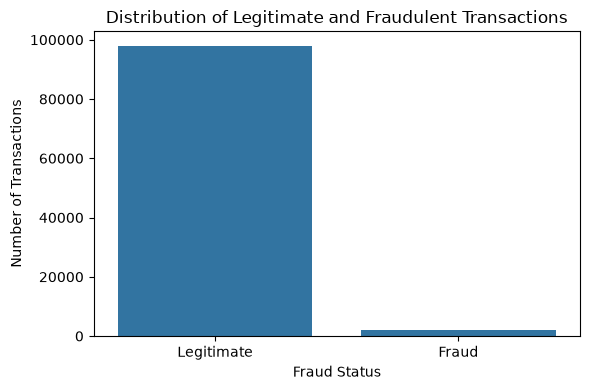

In [25]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=clean_df,
    x='is_fraud'
)

plt.title('Distribution of Legitimate and Fraudulent Transactions')
plt.xlabel('Fraud Status')
plt.ylabel('Number of Transactions')
plt.xticks(
    [0, 1],
    ['Legitimate', 'Fraud']
)

plt.tight_layout()
plt.show()

Visual Assessment of Class Imbalance

The class distribution shows a substantial imbalance between legitimate and fraudulent transactions.

Legitimate transactions account for 97.945% of the dataset, while fraudulent transactions represent only 2.055%.

The visual difference demonstrates why classification accuracy alone would be misleading. A model could achieve very high accuracy by predominantly predicting the majority class while failing to detect fraudulent transactions.

This class imbalance will therefore be considered during model development, training, validation, and performance evaluation.

3. Initial Data Understanding Summary

The initial assessment identified the following characteristics of the dataset:

The dataset contains 100,000 transactions and 43 variables.
Transactions cover approximately one full year, from January to December 2026.
No completely duplicated records or duplicated transaction IDs were identified.
Browser information is missing for ATM and In-store transactions, indicating structurally non-applicable values rather than random missingness.
Fraud represents 2.055% of transactions, creating a highly imbalanced classification problem.
Card-Not-Present is the most frequently observed fraud category.
Fraudulent transactions have higher average and median transaction amounts than legitimate transactions.
Fraudulent transactions show higher short-term transaction velocity.
Fraudulent transactions are associated with greater geographic distance from home and the previous transaction.
International and high-risk-country transactions show higher observed fraud rates within this dataset.
Individual variables should not be interpreted as standalone fraud rules because legitimate and fraudulent activity overlap across the observed characteristics.
These initial findings will guide the subsequent data preparation, exploratory analysis, feature assessment, and predictive-modelling stages.